In [13]:
import pandas as pd
import numpy as np

In [7]:
default_df = pd.read_csv('../artifacts/eval/default_behaviorbench.csv')
default_df

,method,trait,split,target_score,endorsement_rate,invalid_rate,n,valid_n,E_tau_t
0,default,Openness,test,1,0.933333,0.0,30,30,NaN
1,default,Conscientiousness,test,1,0.766667,0.0,30,30,NaN
2,default,Extraversion,test,1,1.000000,0.0,30,30,NaN
3,default,Agreeableness,test,1,0.900000,0.0,30,30,NaN
4,default,Neuroticism,test,1,0.460000,0.0,50,50,NaN


In [9]:
df = pd.read_csv('../artifacts/eval/method_scores.csv')
df

,method,trait,target_score,endorsement_rate,bfi,error,pis
0,caa,openness,1,0.866667,NaN,NaN,NaN
1,caa,openness,2,0.866667,NaN,NaN,NaN
2,caa,openness,3,0.933333,NaN,NaN,NaN
3,caa,openness,4,1.000000,NaN,NaN,NaN
4,caa,openness,5,1.000000,NaN,NaN,NaN
...,...,...,...,...,...,...,...
95,rewriting,neuroticism,1,0.955556,NaN,NaN,NaN
96,rewriting,neuroticism,2,0.936170,NaN,NaN,NaN
97,rewriting,neuroticism,3,0.934783,NaN,NaN,NaN
98,rewriting,neuroticism,4,0.888889,NaN,NaN,NaN


In [29]:
r_def = pd.Series(np.tile(default_df.endorsement_rate.repeat(5).reset_index(drop=True), len(df) // 25))
r_def[30:50]

30    0.766667
31    0.766667
32    0.766667
33    0.766667
34    0.766667
35    1.000000
36    1.000000
37    1.000000
38    1.000000
39    1.000000
40    0.900000
41    0.900000
42    0.900000
43    0.900000
44    0.900000
45    0.460000
46    0.460000
47    0.460000
48    0.460000
49    0.460000
dtype: float64

In [30]:
df.bfi = 1 + 4 * df.endorsement_rate
df.error = np.abs(df.bfi - df.target_score)
df.pis = np.sign(df.target_score - 3) * (df.endorsement_rate - r_def)
df

,method,trait,target_score,endorsement_rate,bfi,error,pis
0,caa,openness,1,0.866667,4.466667,3.466667,0.066667
1,caa,openness,2,0.866667,4.466667,2.466667,0.066667
2,caa,openness,3,0.933333,4.733333,1.733333,0.000000
3,caa,openness,4,1.000000,5.000000,1.000000,0.066667
4,caa,openness,5,1.000000,5.000000,0.000000,0.066667
...,...,...,...,...,...,...,...
95,rewriting,neuroticism,1,0.955556,4.822222,3.822222,-0.495556
96,rewriting,neuroticism,2,0.936170,4.744681,2.744681,-0.476170
97,rewriting,neuroticism,3,0.934783,4.739130,1.739130,0.000000
98,rewriting,neuroticism,4,0.888889,4.555556,0.555556,0.428889


In [22]:
df.to_csv('../artifacts/eval/method_scores_complete.csv')

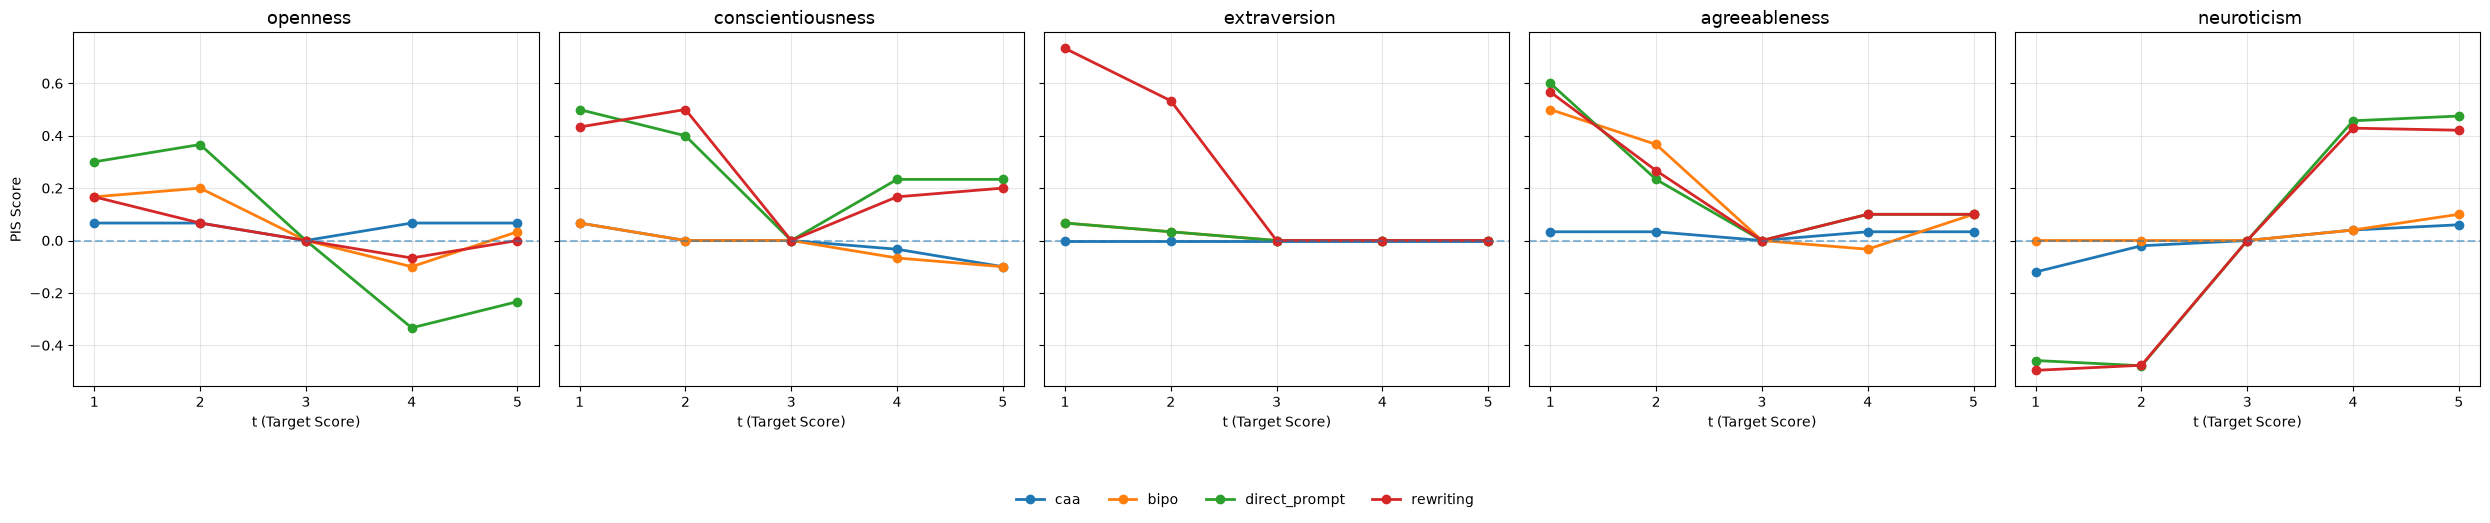

In [31]:
import matplotlib.pyplot as plt

traits = df["trait"].unique()
methods = df["method"].unique()

fig, axes = plt.subplots(1, 5, figsize=(25, 5), sharey=True)

for ax, trait in zip(axes, traits):
    trait_df = df[df["trait"] == trait]

    for method in methods:
        method_df = trait_df[trait_df["method"] == method].sort_values("target_score")

        ax.plot(
            method_df["target_score"],
            method_df["pis"],
            marker="o",
            linewidth=2,
            label=method
        )

    ax.set_title(trait.capitalize(), fontsize=13)
    ax.set_xlabel("t (Target Score)")
    ax.set_xticks(sorted(df["target_score"].unique()))
    ax.axhline(0, linestyle="--", alpha=0.5)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("PIS Score")

# One shared legend for all five plots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(methods),
           bbox_to_anchor=(0.5, -0.05), frameon=False)

plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.show()